In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap.umap_ import UMAP
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from matplotlib.backends.backend_pdf import PdfPages
import pyranges as pr
import pyBigWig
from matplotlib.pyplot import gcf
import os
import re
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage
import matplotlib.patches as patches
import time

# set working directory
os.chdir('/gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/subset_clustering/250kb/all_batches')

def plotheatmap(
    count, 
    filter_xy = True, 
    normalization='global_zscore', 
    metadata=None, 
    cmap='seismic', 
    plotname='heatmap',
    cellid_col = 'prefix',
    plotdis = False,
    colors = [{1: 'red', 2: 'blue', 3: 'green'}, {0: 'orange', 1: 'purple'}],
    extra_cluster = ['cluster'],
    zero_threshold = 0.5,  # Parameter to control the threshold for masking (50% by default)
    vmin=None,  # New parameter: minimum value for colormap
    vmax=None,  # New parameter: maximum value for colormap
    percentile_cap=95,  # New parameter: percentile to cap values if vmax is None
    symmetric_scale=True,  # New parameter: force colormap to be symmetric around center
    cluster_chrom = None,
    subset_var = None,
    subset_label = None,
    num_cluster = 3,
    subcluster_of = None,   # cluster id (from the num_cluster cut) to split further;
                            # 'auto' = the cluster with the largest chr-deviation (tumor)
    subcluster_n = 3,       # how many sub-clones to split that cluster into
    cluster_metric = 'corr',  # 'corr' = 1 - Pearson corr between cells (proper condensed
                              # distance); 'cn' = Euclidean on the CN values themselves
                              # (magnitude-aware -> cleaner tumor/non-tumor first split)
    cluster_method = 'ward',  # scipy linkage method (ward / average / complete / ...)
    precomputed_linkage = None,  # supply a row (cell) linkage computed elsewhere (e.g. the
                                 # chr22q GMM+stitched tree) to drive the SAME heatmap format;
    precomputed_order = None,    #   list of cell names matching that linkage's leaves 0..n-1,
    precomputed_labels = None,   #   and a dict/Series cell -> cluster_cna label to color by.
    show_row_dendrogram = True   # set False to hide the row dendrogram (row ORDER is kept)
    ):
    

    if subset_var != None:
        subset_samples = metadata[metadata[subset_var].isin(subset_label)]['V1']
        metadata_columns = count.columns.tolist()[:3]
        # Find which samples from subset_samples are in count.columns
        shared_samples = [sample for sample in subset_samples if sample in count.columns]
        # Combine the metadata columns with the shared samples
        selected_columns = metadata_columns + shared_samples
        print(selected_columns)
        # Now select only these columns from your dataframe
        count = count[selected_columns]
        metadata = metadata[metadata[subset_var].isin(subset_label)]

    # Make a copy to avoid modifying the original DataFrame
    count_processed = count.copy()
    
    # Extract copy number data (columns 4 and beyond)
    copy_number_cols = count_processed.columns[3:]
    
    if filter_xy:
        # filter out X and Y chromosome
        count_processed = count_processed[~count_processed['chr'].isin(['chrX', 'chrY'])]
    
    # Create a mask for regions where more than zero_threshold of cells have count 0
    zero_mask = (count_processed.iloc[:, 3:] == 0).mean(axis=1) > zero_threshold
    
    # Keep track of masked rows for later use
    masked_rows = count_processed.index[zero_mask]
    
    # Exclude masked regions from normalization (for all normalization methods)
    # Create a temporary view without the masked rows
    temp_data = count_processed[~zero_mask]
    
    if normalization == 'seq_depth':
        # Sequencing depth normalization, excluding masked regions
        for col in copy_number_cols:
            # Get sum of column excluding masked regions
            col_sum = temp_data[col].sum()
            if col_sum > 0:  # Avoid division by zero
                count_processed.loc[~zero_mask, col] = count_processed.loc[~zero_mask, col] / col_sum
    
    elif normalization == 'median':
        # Normalize for sequencing depth using median normalization
        # For each cell (column)
        for col in copy_number_cols:
            # Get non-zero values to calculate median, excluding masked regions
            non_zero_values = temp_data[col][temp_data[col] > 0]
            
            # Skip columns with all zeros to avoid division by zero
            if len(non_zero_values) == 0:
                continue
            
            # Calculate median of non-zero values
            non_zero_median = np.median(non_zero_values)
            
            # Normalize by the median, scaling to diploid (2), only for non-masked regions
            count_processed.loc[~zero_mask, col] = count_processed.loc[~zero_mask, col] / non_zero_median * 2
    
    elif normalization == 'global_zscore':
        # Z-score normalization with global mean and std, excluding masked regions
        mean_global = temp_data.iloc[:, 3:].values.mean()
        std_global = temp_data.iloc[:, 3:].values.std()
        count_processed.loc[~zero_mask, count_processed.columns[3:]] = (
            (count_processed.loc[~zero_mask, count_processed.columns[3:]] - mean_global) / std_global
        )
    
    elif normalization == 'zscore':
        # Z-score normalization with mean and std for each bin independently, excluding masked regions
        for idx in temp_data.index:
            row_values = temp_data.loc[idx, copy_number_cols]
            mean_row = row_values.mean()
            std_row = row_values.std()
            if std_row > 0:  # Avoid division by zero
                count_processed.loc[idx, copy_number_cols] = (row_values - mean_row) / std_row

    if precomputed_linkage is not None:
        # Use a row (cell) linkage + labels computed OUTSIDE (e.g. the chr22q GMM +
        # stitched tree). Reorder the cell columns to match the supplied linkage's leaves,
        # then fall through to the SAME rendering below (genome bins, seismic, chr
        # boundaries, row_colors) UNCHANGED -- only the dendrogram + cluster_cna differ.
        order = list(precomputed_order)
        count_processed = count_processed[['chr', 'start', 'end'] + order]
        linkage_matrix = np.asarray(precomputed_linkage, dtype=float)
        cluster_labels = np.array([int(precomputed_labels[c]) for c in order])
    else:
        if cluster_chrom != None:
            count_processed_sub = count_processed[count_processed['chr'].isin(cluster_chrom)]
        else:
            count_processed_sub = count_processed
        cluster_vals = count_processed_sub[count_processed_sub.columns.tolist()[3:]]  # bins x cells

        # Build the row (cell) dendrogram. Two options:
        #  - 'corr': 1 - Pearson correlation between cells, passed as a PROPER CONDENSED
        #    distance (squareform). NOTE: the old code did linkage(square_matrix, 'ward'),
        #    which scipy silently treats as observation vectors (clustering the distance
        #    profiles, not the distances) -> unstable first split. This path fixes that.
        #  - 'cn': cluster on the copy-number values directly (Euclidean); magnitude-aware,
        #    so large-amplitude losses (tumor) separate from flat (non-tumor) more cleanly.
        distance = 1 - cluster_vals.corr()
        if cluster_metric == 'cn':
            obs = cluster_vals.T.values                        # cells x bins
            obs = obs[:, np.all(np.isfinite(obs), axis=0)]     # drop non-finite bins
            linkage_matrix = linkage(obs, method=cluster_method)
        else:  # 'corr'
            dsq = distance.fillna(1.0).values
            np.fill_diagonal(dsq, 0.0)
            linkage_matrix = linkage(squareform(dsq, checks=False), method=cluster_method)

        cluster_labels = fcluster(linkage_matrix, num_cluster, criterion='maxclust')

        # --- optional: keep one cluster as-is and split another into sub-clones -------
        # maxclust always carves the largest-height splits first, which here keeps
        # subdividing the (heterogeneous) non-tumor branch. To instead split the tumor
        # branch, we cut the SAME linkage_matrix deeper (raising k one split at a time)
        # until the tumor clade is divided into `subcluster_n` sub-clades, then merge all
        # the (kept) non-tumor clades back to one label. Because the labels come from the
        # very tree that is drawn on the heatmap, every cluster is a contiguous clade of
        # that dendrogram -> the cluster_cna row-colors line up exactly with the tree.
        if subcluster_of is not None:
            cells_order = count_processed.columns.tolist()[3:]
            base = pd.Series(cluster_labels, index=cells_order)
            center_for_dev = 0 if normalization in ['global_zscore', 'zscore'] else 2
            sub_vals = count_processed_sub[count_processed_sub.columns.tolist()[3:]]
            if subcluster_of == 'auto':
                dev = {c: (sub_vals.loc[:, base.index[base == c]] - center_for_dev)
                            .abs().mean().mean()
                       for c in sorted(base.unique())}
                subcluster_of = max(dev, key=dev.get)
                print('subcluster_of="auto" -> cluster {} (largest |dev| on {})'.format(
                    subcluster_of, cluster_chrom))
            tumor_cells = base.index[base == subcluster_of]
            # raise k on the SAME tree until the tumor clade holds subcluster_n sub-clades
            k = num_cluster
            lab_k = base
            while lab_k.loc[tumor_cells].nunique() < subcluster_n and k < len(cells_order):
                k += 1
                lab_k = pd.Series(fcluster(linkage_matrix, k, criterion='maxclust'),
                                  index=cells_order)
            # relabel: all kept (non-tumor) clades -> 1; tumor sub-clades -> 2..1+subcluster_n
            sub_ids = sorted(lab_k.loc[tumor_cells].unique())
            remap = {old: i + 2 for i, old in enumerate(sub_ids)}
            final = pd.Series(1, index=cells_order)
            final.loc[tumor_cells] = lab_k.loc[tumor_cells].map(remap)
            cluster_labels = final.loc[cells_order].astype(int).values
            print('sub-clade cut reached at k={}; '.format(k)
                  + 'sub-clones {}'.format(dict(pd.Series(cluster_labels).value_counts().sort_index())))

    metadata.index = metadata[cellid_col]
    metadata = metadata.loc[count_processed.columns[3:]]
    metadata['cluster_cna'] = cluster_labels
    metadata['clone'] = ['clone{}'.format(i) for i in cluster_labels]
    metadata['cna_cluster_color'] = metadata['cluster_cna'].map(colors[0])
    
    row_colors_cluster_1 = metadata['cluster_cna'].map(colors[0])
    cluster_color_dic = {}
    cluster_color_dic['CNA cluster'] = row_colors_cluster_1
    
    if len(extra_cluster) > 0:
        for i in range(len(extra_cluster)):
            cluster_color_dic[extra_cluster[i]] = metadata[extra_cluster[i]].map(colors[i+1])
            
    row_colors_df = pd.DataFrame(cluster_color_dic)

    chromosome_positions = count_processed['chr'].factorize()[0]  # Numeric encoding of chromosomes
    boundary_indices = [0] + list((chromosome_positions[:-1] != chromosome_positions[1:]).nonzero()[0] + 1)
    chromosome_labels = count_processed['chr'].unique()
    
    # Determine center value for color map based on normalization
    center = 0 if normalization in ['global_zscore', 'zscore'] else 2

    # Create a custom colormap with black for masked values
    if 'seismic' in cmap:
        # Get the original colormap
        original_cmap = plt.cm.seismic
        # Create a modified colormap with black for masked values
        cmap_with_mask = original_cmap.copy()
        cmap_with_mask.set_bad('black')
    else:
        # For other colormaps
        original_cmap = plt.cm.get_cmap(cmap)
        cmap_with_mask = original_cmap.copy()
        cmap_with_mask.set_bad('black')
    
    # Convert data to NumPy array for masking
    heatmap_data = count_processed.iloc[:, 3:].T.values
    
    # Create a mask where the data should be black
    mask_array = np.zeros_like(heatmap_data, dtype=bool)
    for i, idx in enumerate(count_processed.index):
        if idx in masked_rows:
            mask_array[:, i] = True
    
    # Apply the mask
    masked_data = np.ma.array(heatmap_data, mask=mask_array)
    
    # Create DataFrame for clustermap
    masked_df = pd.DataFrame(masked_data, 
                         index=count_processed.columns[3:], 
                         columns=count_processed.index)
    
    # Determine color scale limits based on the data, excluding masked regions
    valid_data = heatmap_data[~mask_array]
    
    # Set vmin and vmax based on specified parameters or calculated from data
    if vmin is None:
        if normalization in ['global_zscore', 'zscore']:
            # For z-scores, we typically want a symmetric scale
            vmin = np.percentile(valid_data, 100 - percentile_cap) if symmetric_scale else np.min(valid_data)
        else:
            # For copy number data, minimum is usually 0 (homozygous deletion)
            vmin = 0
    
    if vmax is None:
        if normalization in ['global_zscore', 'zscore'] and symmetric_scale:
            # For z-scores with symmetric scale, use the same magnitude as vmin
            vmax = abs(vmin)
        else:
            # Otherwise use percentile cap
            vmax = np.percentile(valid_data, percentile_cap)
    
    g = sns.clustermap(masked_df,
                   row_linkage=linkage_matrix, 
                   col_cluster=False, 
                   cmap=cmap_with_mask, 
                   yticklabels=False, 
                   xticklabels=False, 
                   row_colors=row_colors_df,
                   center=center,
                   mask=mask_array,
                   vmin=vmin,  # Apply the color scale minimum
                   vmax=vmax)  # Apply the color scale maximum

    g.cax.set_visible(False)
    if not show_row_dendrogram:
        g.ax_row_dendrogram.set_visible(False)   # keep the row order, hide the tree

    for boundary in boundary_indices:
        g.ax_heatmap.axvline(x=boundary, color='black', linewidth=1.5)

    for i, label in enumerate(chromosome_labels):
        if i < len(boundary_indices) - 1:
            x_position = (boundary_indices[i] + boundary_indices[i + 1]) / 2
        else:
            x_position = (boundary_indices[i] + g.ax_heatmap.get_xlim()[1]) / 2
        g.ax_heatmap.text(x_position, -0.02, label, ha='center', va='top', color='black', fontsize=7, rotation=90, transform=g.ax_heatmap.get_xaxis_transform())

    # sidebar (row_colors) labels: 45 deg + larger for publication
    for _t in g.ax_row_colors.get_xticklabels():
        _t.set_rotation(45); _t.set_horizontalalignment('right'); _t.set_fontsize(13)

    plt.title(plotname.split('/')[-1])
    plt.savefig(plotname+'.pdf')  
    plt.show()
    
    if plotdis:
        # Exclude masked regions from the histogram
        values_to_plot = count_processed.loc[~zero_mask, count_processed.columns[3:]].values.flatten()
        
        # Plot histogram of values with vertical lines showing the color scale limits
        plt.figure(figsize=(10, 6))
        plt.hist(values_to_plot, bins=100)
        plt.axvline(x=vmin, color='red', linestyle='--', label=f'vmin = {vmin:.2f}')
        plt.axvline(x=vmax, color='red', linestyle='--', label=f'vmax = {vmax:.2f}')
        if center != 0:
            plt.axvline(x=center, color='black', linestyle='-', label=f'center = {center}')
        plt.xlabel('Values' if normalization == 'median' else 'Z-score')
        plt.ylabel('Frequency')
        plt.title(f'Distribution of {"Copy Number Values" if normalization == "median" else "Z-scores"} (Excluding Masked Regions)')
        plt.legend()
        plt.savefig(plotname+f'.{"copy_number" if normalization == "median" else "zscore"}_distribution.png')
        plt.show()

    return linkage_matrix, metadata

# Copy-number heatmap — all_batches (meningioma)

CNA (1Mb fragment-count) heatmap for the **all_batches** cell set, mimicking `Combined_sample2/CNA.ipynb` (`plotheatmap`). Input `CNA.1M.txt` is generated from the new consolidated run's `04.alignment_snakemake` BEDs by `code/build_cna_1M.sh` (count_fragment.py, 1Mb bins). Rows = cells (ward-clustered on chr14/chr22), columns = genome bins; median-normalized, group (sample_plate) row-colors.

In [3]:
# Load CNA 1Mb fragment counts (new consolidated run) + build batch metadata
CNA1M = "/gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/subset_clustering/250kb/CNA.1M.txt"   # shared, generated by code/build_cna_1M.sh
PASSED = "/gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake/QC/meningioma_passed_hicusable.txt"

cna = pd.read_csv(CNA1M, sep="\t")

import re as _re
def assign_group(p):
    if p.startswith("NU04113_scNOMe_HiC_p2_"): return "patient2_plate2"
    if p.startswith("NU04113_"): return "patient2_plate1"
    if p.startswith("MY_"):
        m = _re.match(r"MY_(\d+)_", p); n = int(m.group(1)) if m else 999
        return "patient1_plate1" if n <= 24 else "patient1_plate2"
    return "other"

passed = [l.strip() for l in open(PASSED) if l.strip()]
cells = [c for c in passed if c in cna.columns]          # cells present in CNA.1M
print(f"{len(cells)} / {len(passed)} passed cells have CNA columns")

meta = pd.DataFrame({"cell": cells})
meta["library"]  = meta["cell"].map(assign_group)
meta["patient"] = meta["library"].str.replace(r"_plate.*", "", regex=True)
meta["plate"]  = meta["library"].str.replace(r".*_", "", regex=True)
meta["seqbatch"] = meta["cell"].map(lambda p: "batch3" if p.startswith("NU04113_scNOMe_HiC_p2_") else ("batch2" if p.startswith("NU04113_") else ("batch1" if p.startswith("MY_") else "other")))
meta.index = meta["cell"]

cna = cna[["chr", "start", "end"] + cells]
cna.head()

292 / 292 passed cells have CNA columns


,chr,start,end,MY_10_S193.ATCACG,MY_10_S193.GCCAAT,MY_10_S193.TGACCA,MY_11_S194.ATCACG,MY_11_S194.GCCAAT,MY_12_S195.ATCACG,MY_12_S195.GCCAAT,...,NU04113_scNOMe_HiC_p2_19_250409_S19.CGATGT,NU04113_scNOMe_HiC_p2_19_250409_S19.GCCAAT,NU04113_scNOMe_HiC_p2_19_250409_S19.TGACCA,NU04113_scNOMe_HiC_p2_20_250409_S20.CGATGT,NU04113_scNOMe_HiC_p2_20_250409_S20.GCCAAT,NU04113_scNOMe_HiC_p2_20_250409_S20.TGACCA,NU04113_scNOMe_HiC_p2_21_250409_S21.ATCACG,NU04113_scNOMe_HiC_p2_21_250409_S21.CGATGT,NU04113_scNOMe_HiC_p2_21_250409_S21.GCCAAT,NU04113_scNOMe_HiC_p2_21_250409_S21.TGACCA
0,chr1,1,1000000,297.0,169.0,282.0,63.0,87.0,40.0,72.0,...,42.0,37.0,52.0,61.0,65.0,54.0,59.0,52.0,73.0,41.0
1,chr1,1000001,2000000,1720.0,1093.0,1645.0,526.0,543.0,220.0,350.0,...,198.0,306.0,234.0,235.0,277.0,237.0,377.0,326.0,337.0,324.0
2,chr1,2000001,3000000,1927.0,1248.0,1577.0,537.0,674.0,273.0,481.0,...,275.0,336.0,313.0,223.0,313.0,311.0,419.0,359.0,389.0,335.0
3,chr1,3000001,4000000,2233.0,1276.0,2009.0,633.0,568.0,246.0,518.0,...,303.0,370.0,337.0,272.0,355.0,298.0,502.0,402.0,461.0,385.0
4,chr1,4000001,5000000,1808.0,994.0,1638.0,465.0,491.0,222.0,428.0,...,247.0,326.0,240.0,194.0,281.0,226.0,383.0,289.0,364.0,358.0


subcluster_of="auto" -> cluster 1 (largest |dev| on ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22'])
sub-clade cut reached at k=10; sub-clones {1: np.int64(179), 2: np.int64(55), 3: np.int64(57), 4: np.int64(1)}


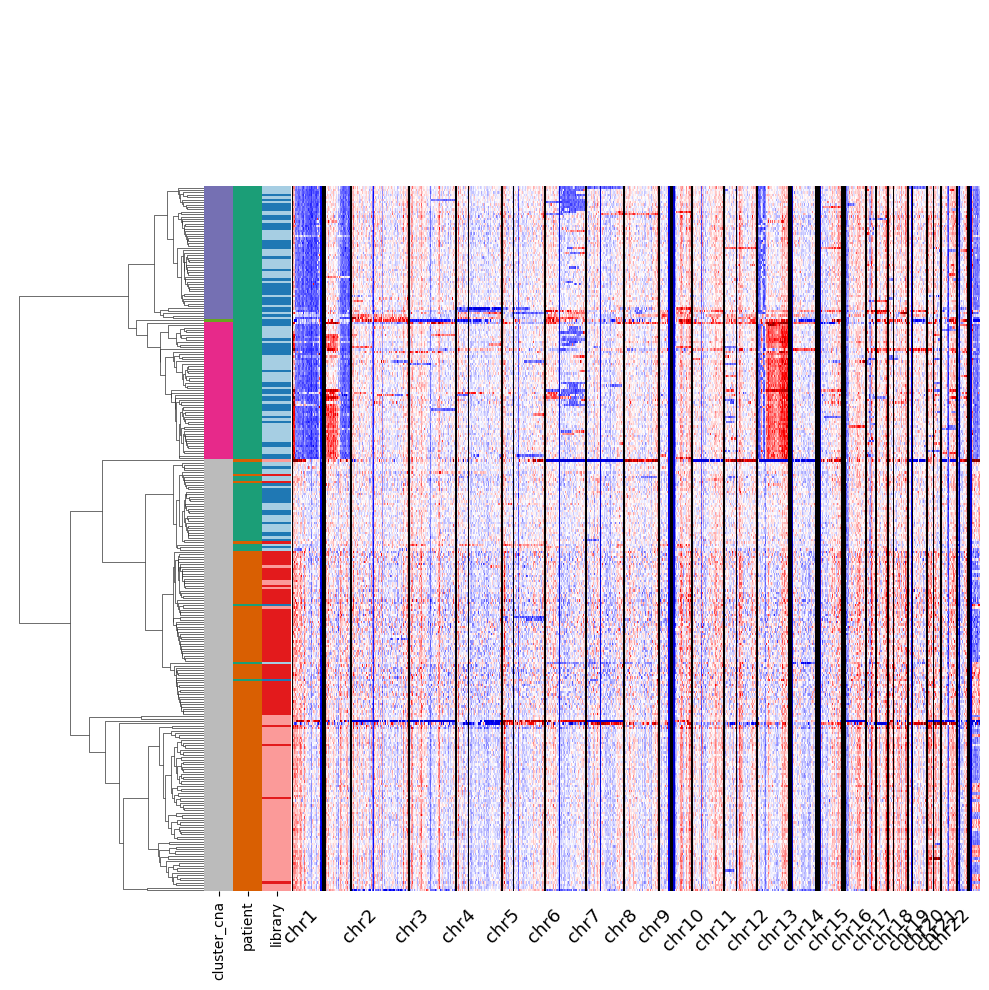

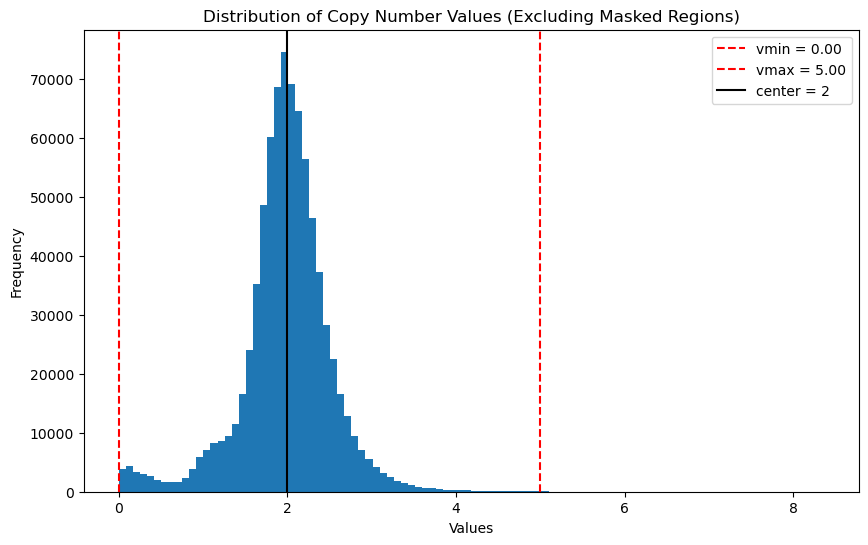

saved figures/cna.pdf + tables/cna_metadata_clusters.txt


cluster_cna
1    179
2     55
3     57
4      1
Name: count, dtype: int64

In [4]:
# Copy-number heatmap (cells x 1Mb bins), median-normalized, row-clustered.
# Dendrogram: GENOME-WIDE clustering on the copy-number VALUES (cluster_metric="cn",
# Euclidean + ward). Magnitude-aware + genome-wide gives the cleanest, most stable
# tumor(structured)/non-tumor(flat) FIRST split. (chr14/chr22-only was unstable and
# leaked tumor cells into the non-tumor side; adding chromosomes stabilizes the split.)
#
# Two-stage clustering: a plain num_cluster cut keeps subdividing the heterogeneous
# NON-tumor branch first, so you cannot get "tumor -> 3" just by raising the number.
# Instead we cut at num_cluster=2 (tumor vs non-tumor), then cut the SAME dendrogram
# deeper until the tumor clade splits into 3, and merge all non-tumor clades back to 1
# (subcluster_of/subcluster_n). Labels come from the tree that is drawn, so the
# cluster_cna row-colors line up exactly with the left dendrogram.
#   -> cluster 1 = non-tumor, clusters 2/3/4 = tumor sub-clones (4 total).
# subcluster_of="auto" picks the cluster with the largest chr14/chr22 deviation (= tumor).
# If auto picks the wrong one, set subcluster_of=1 or =2 explicitly (look at the heatmap).
# distinct palette per sidebar track (kept consistent with the exploration notebook):
#   cluster_cna/clone = grey + purple/magenta/olive/gold ; sample = teal/orange ; group = blue/red
clone_color  = {1: "#BBBBBB", 2: "#7570B3", 3: "#E7298A", 4: "#66A61E", 5: "#E6AB02"}  # 1=non-tumor (grey)
patient_color = {"patient1": "#1B9E77", "patient2": "#D95F02"}
library_color  = {"patient1_plate1": "#1F78B4", "patient1_plate2": "#A6CEE3",
                "patient2_plate1": "#E31A1C", "patient2_plate2": "#FB9A99"}

link, newmeta = plotheatmap(
    cna, metadata=meta, plotname="figures/cna",
    cellid_col="cell", extra_cluster=["patient", "library"],
    num_cluster=2, subcluster_of="auto", subcluster_n=3,
    colors=[clone_color, patient_color, library_color],
    zero_threshold=0.3, normalization="median", vmin=0, vmax=5,
    cluster_chrom=[f"chr{i}" for i in range(1, 23)],   # genome-wide (all autosomes)
    cluster_metric="cn", cluster_method="ward",         # magnitude-aware Euclidean+ward
    plotdis=True,
)
newmeta.to_csv("tables/cna_metadata_clusters.txt", sep="\t")
print("saved figures/cna.pdf + tables/cna_metadata_clusters.txt")
newmeta["cluster_cna"].value_counts().sort_index()

## chr22q (NF2) tumor/normal calling — three approaches

The genome-wide `plotheatmap` above does **not** separate the chr22q-loss tumor from normal (chr22p is unmappable noise; whole-genome clustering is dominated by per-bin noise + batch). These cells drive the split with **chr22q**, then render with the **same `plotheatmap`** (identical genome heatmap) via `precomputed_linkage`/`order`/`labels` — only the row dendrogram + `cluster_cna` change. **Approach 1** (GMM on chr22q + a stitched dendrogram) imposes normal/tumor as the first split — cleanest, exact. **Approach 2** up-weights chr22q as a feature in a single ward tree — simpler but approximate. **Approach 3** uses chr1p + chr22q arm status (GMM per arm) to impose **three groups** (1=normal, 2=chr22q-loss, 3=chr22q+chr1p-loss = progression), stitched + rendered the same way. Row tracks: `cluster_cna` (1=normal grey, 2/3 tumor), `sample`, `group`. Tune `SUBCLONE_N` / `ARM_WEIGHT` in the helpers cell.

In [5]:
# chr22q (NF2)-based tumor/normal calling — shared helpers.
# Whole-chr22 is misleading (chr22p is unmappable, ~CN 0 everywhere). chr22q is bimodal:
# a normal population (diploid ~2) and a loss/tumor population (~1.3). Generic genome-wide
# clustering is dominated by per-bin noise + batch and does NOT recover it, so we compute a
# chr22q-driven row (cell) clustering here, then render it with the SAME plotheatmap as
# above (identical genome heatmap format) via precomputed_linkage/order/labels.
import numpy as np, pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.mixture import GaussianMixture

# hg38 centromere positions (bp) to split each chromosome into p/q arms
CEN = {f"chr{i}": v*1e6 for i, v in zip(range(1, 23),
      [123.4,93.9,90.9,50,48.8,59.8,60.1,45.2,43,39.8,53.4,35.5,17.7,17.2,19,36.8,25.1,18.5,26.2,28.1,12,15])}
# same DISTINCT row-color palettes as the main heatmap (colors[0]=clone, [1]=sample, [2]=group);
# kept consistent with the exploration notebook (CLONE_PAL / PATIENT_PAL / LIBRARY_PAL).
clone_color  = {1:"#BBBBBB", 2:"#7570B3", 3:"#E7298A", 4:"#66A61E", 5:"#E6AB02"}  # 1=normal(grey)
patient_color = {"patient1":"#1B9E77", "patient2":"#D95F02"}                          # teal/orange
library_color  = {"patient1_plate1":"#1F78B4","patient1_plate2":"#A6CEE3",             # blue/red
                "patient2_plate1":"#E31A1C","patient2_plate2":"#FB9A99"}
SUBCLONE_N = 2   # how many tumor sub-clones
MIN_CLONE  = 10  # a tumor sub-clone smaller than this is treated as an OUTLIER (folded into
                 # its nearest sub-clone) instead of forming its own early-branching clade
ARM_WEIGHT = 6.0 # chr22q up-weighting for Approach 2

def median_norm(cna, cells):        # per-cell: divide by non-zero median, scale to 2
    v = cna[cells].astype(float).copy()
    for c in cells:
        nz = v[c][v[c] > 0]
        if len(nz): v[c] = v[c] / np.median(nz) * 2
    return pd.concat([cna[["chr","start","end"]], v], axis=1)

def arm_means(norm, cells):         # cells x arms; drop unmappable acrocentric p-arms
    a = norm["chr"] + np.where(norm["start"] < norm["chr"].map(CEN), "p", "q")
    arms = [f"chr{i}{s}" for i in range(1,23) for s in "pq"]
    A = pd.DataFrame({ar: norm[a==ar][cells].replace([np.inf,-np.inf],np.nan).mean(axis=0)
                      for ar in arms if (a==ar).any()})
    return A[[ar for ar in A.columns if A[ar].median() > 0.5]].clip(upper=3.0)

def gmm_split(chr22q):              # 2-component GMM -> normal(high) vs loss(low), valley thr
    g = GaussianMixture(2, random_state=0).fit(chr22q.values.reshape(-1,1))
    mu = g.means_.ravel(); hi = int(np.argmax(mu))
    xs = np.linspace(min(mu), max(mu), 4000)
    thr = xs[np.argmin(np.abs(g.predict_proba(xs.reshape(-1,1))[:, hi] - 0.5))]
    return chr22q >= thr, float(thr)

def stitch(Za, na, Zb, nb, gap=1.15):  # splice two linkages under one root (A then B leaves)
    n = na + nb; Za = np.array(Za, float); Zb = np.array(Zb, float)
    for r in range(len(Za)):
        for c in (0,1):
            if Za[r,c] >= na: Za[r,c] += nb
    binc = n + na - 1 - nb
    for r in range(len(Zb)):
        for c in (0,1):
            Zb[r,c] += na if Zb[r,c] < nb else binc
    rootA = (n+na-2) if na >= 2 else 0
    rootB = (2*n-3)  if nb >= 2 else na
    hmax = max(Za[:,2].max() if len(Za) else 0, Zb[:,2].max() if len(Zb) else 0, 1e-6)
    return np.vstack([x for x in (Za, Zb, np.array([[rootA, rootB, hmax*gap, n]])) if len(x)])

def stitch_blocks(groups):          # chain-splice a list of cell-groups into one linkage
    order = list(groups[0]); Z = linkage(Zsc.loc[order].values, "ward"); n = len(order)
    for gr in groups[1:]:
        Zg = linkage(Zsc.loc[gr].values, "ward")
        Z = stitch(Z, n, Zg, len(gr)); order += list(gr); n += len(gr)
    return Z, order

def split_clean(members, k, min_size):
    # split `members` into k sub-clones, but PEEL cells that branch off into clusters
    # smaller than min_size (outliers) and fold each into its nearest sub-clone centroid.
    # Avoids a single outlier hijacking the earliest split.
    Z = linkage(Zsc.loc[members].values, "ward")
    kk = k; lab = pd.Series(fcluster(Z, kk, "maxclust"), index=members)
    while kk < len(members):
        vc = lab.value_counts()
        if lab.nunique() >= k and vc.iloc[k-1] >= min_size:
            break
        kk += 1; lab = pd.Series(fcluster(Z, kk, "maxclust"), index=members)
    big = lab.value_counts().index[:k].tolist()
    groups = [lab.index[lab == b].tolist() for b in big]
    outliers = [c for c in members if lab[c] not in big]
    cents = [Zsc.loc[gr].mean() for gr in groups]
    for c in outliers:                                     # fold outlier into nearest sub-clone
        d = [((Zsc.loc[c] - ct)**2).sum() for ct in cents]
        groups[int(np.argmin(d))].append(c)
    if outliers:
        print(f"  peeled {len(outliers)} outlier tumor cell(s) into nearest sub-clone")
    return groups

# shared inputs (from the load cell above): cna (chr,start,end + cells), meta
norm22 = median_norm(cna, cells)
A      = arm_means(norm22, cells)
Zsc    = ((A - A.mean()) / A.std()).fillna(0)        # z-scored arm features (equal weight)
chr22q = A["chr22q"]
is_normal, thr22 = gmm_split(chr22q)
normal_cells = [c for c in cells if is_normal[c]]
tumor_cells  = [c for c in cells if not is_normal[c]]
print(f"chr22q GMM threshold = {thr22:.2f}  ->  normal {len(normal_cells)} / tumor {len(tumor_cells)}")
print("normal by batch:", dict(meta.loc[normal_cells, "seqbatch"].value_counts()))

chr22q GMM threshold = 1.59  ->  normal 97 / tumor 195
normal by batch: {'batch1': np.int64(41), 'batch3': np.int64(29), 'batch2': np.int64(27)}


### Approach 3 — chr1p + chr22q -> three groups (normal / 22q-loss / 22q+1p-loss)

chr22q thr=1.59  chr1p thr=1.63
3-group sizes (1=normal, 2=22q-loss, 3=22q+1p-loss): {1: np.int64(96), 2: np.int64(90), 3: np.int64(106)}
group x seqbatch:
seqbatch   batch1  batch2  batch3
cna_group                        
1              40      27      29
2               5      40      45
3             105       0       1


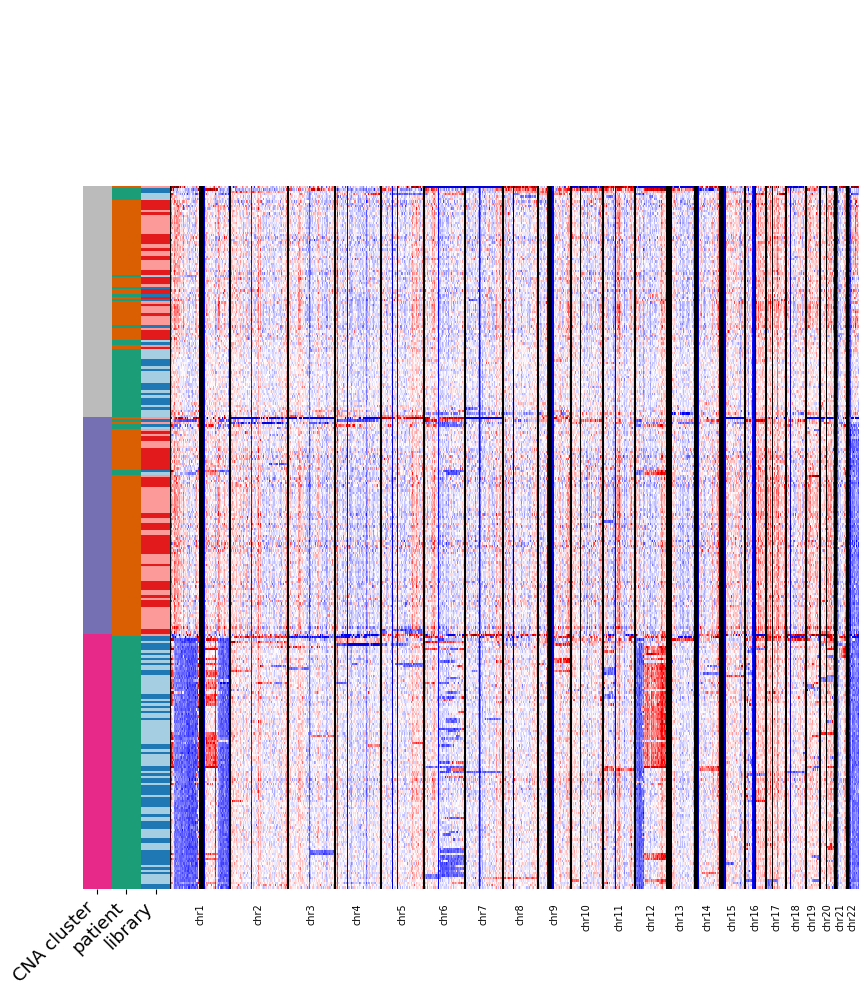

saved figures/cna_approach3_chr1p_chr22q.pdf


In [14]:
# === Approach 3: chr1p + chr22q -> THREE groups, ORIGINAL plotheatmap ==========
# Meningioma: chr22q (NF2) loss is the truncal tumor event; chr1p loss marks progression.
# 3 groups: 1 = normal (chr22q intact), 2 = tumor chr22q-loss (chr1p intact),
#           3 = tumor chr22q-loss + chr1p-loss.  Split imposed on chr1p/chr22q arm status
# (2-component GMM per arm), then the SAME plotheatmap renders it (genome heatmap).
chr1p = A["chr1p"]
norm22, t22 = gmm_split(chr22q)          # True = chr22q intact (normal)
norm1p, t1p = gmm_split(chr1p)           # True = chr1p intact
loss22 = ~norm22; loss1p = ~norm1p
grp3 = pd.Series(1, index=cells)                      # 1 = normal (chr22q intact)
grp3[loss22 & ~loss1p] = 2                            # chr22q loss only
grp3[loss22 &  loss1p] = 3                            # chr22q + chr1p loss
grp3[~loss22 & loss1p] = 2                            # (rare) chr1p-only loss -> tumor grp 2
# keep every group >= 2 cells (fold any tiny group into the largest so ward/stitch works)
vc = grp3.value_counts(); big = vc.index[0]
for g in vc.index[vc < 2]:
    grp3[grp3 == g] = big
present = [g for g in (1, 2, 3) if (grp3 == g).sum() >= 2]
group_lists = [[c for c in cells if grp3[c] == g] for g in present]   # ordered normal->1p+22q
Zstitch3, order3 = stitch_blocks(group_lists)
print(f"chr22q thr={t22:.2f}  chr1p thr={t1p:.2f}")
print("3-group sizes (1=normal, 2=22q-loss, 3=22q+1p-loss):",
      dict(grp3.value_counts().sort_index()))
print("group x seqbatch:")
print(pd.crosstab(grp3.rename("cna_group"), meta.loc[cells, "seqbatch"]))
link3, nm3 = plotheatmap(
    cna, metadata=meta.copy(), plotname="figures/cna_approach3_chr1p_chr22q",
    cellid_col="cell", extra_cluster=["patient", "library"],
    colors=[clone_color, patient_color, library_color],
    zero_threshold=0.3, normalization="median", vmin=0, vmax=5, plotdis=False,
    precomputed_linkage=Zstitch3, precomputed_order=order3, precomputed_labels=grp3.to_dict(),
    show_row_dendrogram=False)      # groups are imposed by chr1p/chr22q -> no tree needed
nm3.to_csv("tables/cna_approach3_clusters.txt", sep="\t")
print("saved figures/cna_approach3_chr1p_chr22q.pdf")